# Task 2 for Homework 4
Class: EDS 220 \
Author: [Calvin Fu](github.com/cuvlin) \
Date: 18, November, 2026 \
Github Repository: [HMWK4 REPO](https://github.com/cuvlin/eds220-hwk4.git)

In [1]:
# Loading in Required Packages
import os
import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import xarray as xr 
import rioxarray as rioxr


### 2. Fire premimeter data exploration
For the shapefiles for the Palisades and Eaton fires, we went to the County of Los Angeles. Both datasets were accessed through [this link](https://egis-lacounty.hub.arcgis.com/maps/ad51845ea5fb4eb483bc2a7c38b2370c/about) on Wednesday November 18, 2026. The shapefiles, give to usby the county of Los Angeles, were derived by CAL FIRE's Historical Fire Permiterer Dataset. \

Below is my preliminary exploration:

In [4]:
# Loading in the shapefiles
root = os.path.join('data', 'Eaton_Perimeter_20250121', 'Eaton_Perimeter_20250121.shp')
eaton = gpd.read_file(root)

root = os.path.join('data', 'Palisades_Perimieter_20250121', 'Palisades_Perimieter_20250121.shp')
palisades = gpd.read_file(root)

In [11]:
# Look at crs of both shapefiles
print('Eaton CRS: ', eaton.crs, '\n')
print('Palisades CRS: ', palisades.crs)

# Check if CRS match
assert palisades.crs == eaton.crs




Eaton CRS:  EPSG:4269 

Palisades CRS:  EPSG:4269


In [10]:
# Check to see if the CRS's are projected
print('Is Eaton a projected crs: ', eaton.crs.is_projected)
print('IS Palisades a projected crs: ', palisades.crs.is_projected)

Is Eaton a projected crs:  False
IS Palisades a projected crs:  False


In [ ]:
# Geometry type
print(palisades.geom_type)
print(eaton.geom_type)

0    MultiPolygon
dtype: object
0    MultiPolygon
dtype: object


In [17]:
# Explore the shapefiles
eaton.explore()
palisades.explore()

Summary of findings: \
Both of thesse shapefiles have the same CRS: EPSG 4269. This CRS is **not** a projeced CRS. This means that both of the CRS's for this dataset are geogrpahic CRS's. By looking at the geometry types of both the datasets, we see that they are both class `MULTIPOLYGON`. This means that there are several parts to the fire, clueing us into the idea that the fire may have jumped and left some areas unburned. By using the `.explore()` method on these shapefiles, we are able to see the area where these fires burned: on the north and northeast sides of LA county.

### 3. NetCDF data import and exploration

In [20]:
# Import the landsat data
root = os.path.join('data', 'landsat8-2025-02-23-palisades-eaton.nc') 
landsat = xr.open_dataset(root)

In [28]:
# Preliminary exploration of xr.Dataset
print(landsat)

<xarray.Dataset> Size: 78MB
Dimensions:      (y: 1418, x: 2742)
Coordinates:
  * y            (y) float64 11kB 3.799e+06 3.799e+06 ... 3.757e+06 3.757e+06
  * x            (x) float64 22kB 3.344e+05 3.344e+05 ... 4.166e+05 4.166e+05
    time         datetime64[ns] 8B ...
Data variables:
    red          (y, x) float32 16MB 1.024e+04 9.886e+03 ... 1.019e+04 9.967e+03
    green        (y, x) float32 16MB 9.93e+03 9.687e+03 ... 9.984e+03 9.662e+03
    blue         (y, x) float32 16MB 9.29e+03 9.183e+03 ... 9.49e+03 9.187e+03
    nir08        (y, x) float32 16MB 1.331e+04 1.313e+04 ... 1.287e+04 1.306e+04
    swir22       (y, x) float32 16MB 1.43e+04 1.437e+04 ... 1.406e+04 1.329e+04
    spatial_ref  int64 8B 0


Summary of findings: \
By using the native data explorer, I was able to learn quite a bit about this dataset. First, this landsat slice has data for 5 bands: red, green, blue, near infrared, and shortwave infrared. The dimensions for these images are 2742 by 1418, which is in terms of pixels. Knowing the landsat picture size, we could calculate the spatial etent of the image (pixel count * 30 meters). There is three dimensions; x, y, and band. The coordinates are 3.799e+06 3.799e+06 ... 3.757e+06 3.757e+06 for Y, and 3.344e+05 3.344e+05 ... 4.166e+05 4.166e+05 for X (extent).

### 4. Restoring geospatial information


In [32]:
# Print the CRS of this dataset
print('CRS of Landsat dataset: ', landsat.rio.crs)

CRS of Landsat dataset:  None


This is not a geospatial object. The object currently does not have a CRS. We must add it manually.

In [37]:
# Print the CRS using the spatial_ref layer
print(landsat.spatial_ref.crs_wkt)

PROJCS["WGS 84 / UTM zone 11N",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4326"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",-117],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["EPSG","32611"]]


The crs is a projected crs: `EPSG:32611`

In [36]:
# Recovering the geospatial information using rio.write_crs() and print
landsat = landsat.rio.write_crs(landsat.spatial_ref.crs_wkt)
print(landsat.rio.crs)

EPSG:32611


## 5. True Color Image


/opt/anaconda3/envs/eds220-env/lib/python3.11/site-packages/matplotlib/cm.py:478: RuntimeWarning: invalid value encountered in cast
  xx = (xx * 255).astype(np.uint8)


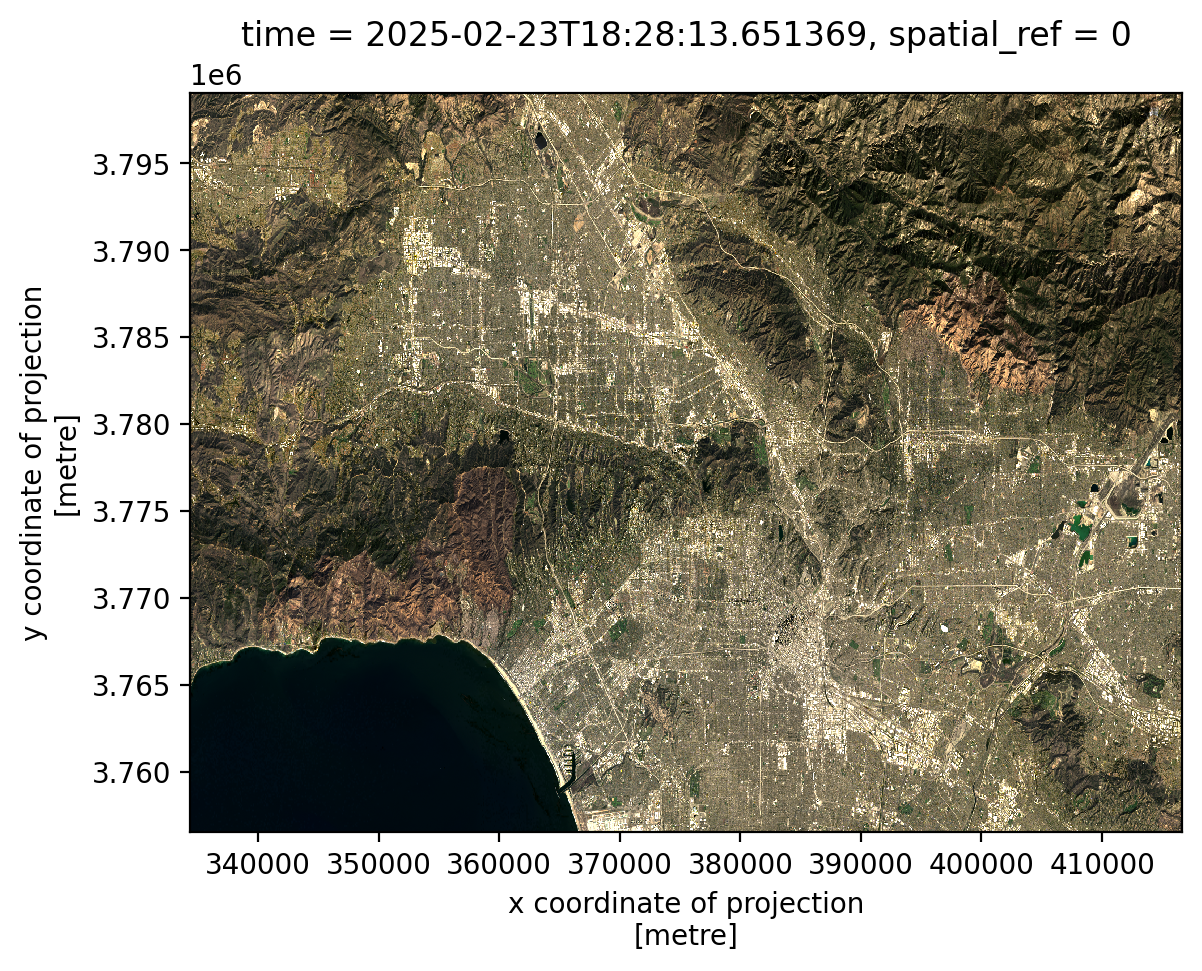

In [64]:
# Plot true color image without creating a new variable
landsat[['red', 'green', 'blue']].to_dataarray().plot.imshow(robust=True)


In [79]:
# Check to see which band has NA values
for band in ['red', 'green', 'blue']:
    print(landsat[[band]].isnull().any())

<xarray.Dataset> Size: 17B
Dimensions:      ()
Coordinates:
    time         datetime64[ns] 8B 2025-02-23T18:28:13.651369
    spatial_ref  int64 8B 0
Data variables:
    red          bool 1B False
<xarray.Dataset> Size: 17B
Dimensions:      ()
Coordinates:
    time         datetime64[ns] 8B 2025-02-23T18:28:13.651369
    spatial_ref  int64 8B 0
Data variables:
    green        bool 1B True
<xarray.Dataset> Size: 17B
Dimensions:      ()
Coordinates:
    time         datetime64[ns] 8B 2025-02-23T18:28:13.651369
    spatial_ref  int64 8B 0
Data variables:
    blue         bool 1B True
